# 🏠 RentRight — Fair Rent Checker for India
**Problem:** People moving to a new city for college or a job often don't know what a *fair* rent is, so they get overcharged.

**What this notebook builds (two ML models):**
1. **Regression model** → predicts the *fair monthly rent* of a flat.
2. **Classification model** → labels a listing as **Bargain / Fair / Overpriced**.

**Data:** ~4,700 real rental listings from 6 Indian cities (Kaggle "House Rent Prediction Dataset").

> How to use: click **Runtime → Run all**. Read the grey explanation above each code block — those are the answers you'll give in an interview.

## Step 1 — Load the data
**What:** read the CSV file into a table (a *DataFrame*).  
**Why:** every ML project starts with looking at the raw data.

In [1]:
import pandas as pd, numpy as np, warnings, joblib
import matplotlib.pyplot as plt, seaborn as sns
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

URL = "https://raw.githubusercontent.com/ataislucky/Data-Science/main/dataset/house_rent_price.csv"
try:
    df = pd.read_csv(URL)
    print("Loaded from the internet ✅")
except Exception as e:
    print("Could not download. Please upload House_Rent_Dataset.csv using the Files panel (left side), then re-run.")
    df = pd.read_csv("House_Rent_Dataset.csv")

print("Rows, columns:", df.shape)
df.head()

Loaded from the internet ✅
Rows, columns: (4746, 12)


,Posted On,BHK,Rent,Size,Floor,Area Type,Area Locality,City,Furnishing Status,Tenant Preferred,Bathroom,Point of Contact
0,5/18/2022,2,10000,1100,Ground out of 2,Super Area,Bandel,Kolkata,Unfurnished,Bachelors/Family,2,Contact Owner
1,5/13/2022,2,20000,800,1 out of 3,Super Area,"Phool Bagan, Kankurgachi",Kolkata,Semi-Furnished,Bachelors/Family,1,Contact Owner
2,5/16/2022,2,17000,1000,1 out of 3,Super Area,Salt Lake City Sector 2,Kolkata,Semi-Furnished,Bachelors/Family,1,Contact Owner
3,7/4/2022,2,10000,800,1 out of 2,Super Area,Dumdum Park,Kolkata,Unfurnished,Bachelors/Family,1,Contact Owner
4,5/9/2022,2,7500,850,1 out of 2,Carpet Area,South Dum Dum,Kolkata,Unfurnished,Bachelors,1,Contact Owner


## Step 2 — Check data quality
**What:** look for missing values and duplicate rows.  
**Why:** bad data gives bad models ("garbage in, garbage out").

In [2]:
print("Missing values:", int(df.isna().sum().sum()))
print("Duplicate rows:", int(df.duplicated().sum()))
df.describe()

Missing values: 0
Duplicate rows: 0


,BHK,Rent,Size,Bathroom
count,4746.000000,4.746000e+03,4746.000000,4746.000000
mean,2.083860,3.499345e+04,967.490729,1.965866
std,0.832256,7.810641e+04,634.202328,0.884532
min,1.000000,1.200000e+03,10.000000,1.000000
25%,2.000000,1.000000e+04,550.000000,1.000000
50%,2.000000,1.600000e+04,850.000000,2.000000
75%,3.000000,3.300000e+04,1200.000000,2.000000
max,6.000000,3.500000e+06,8000.000000,10.000000


## Step 3 — Clean the data & create better features (*Feature Engineering*)
- The **Floor** column looks like `"Ground out of 2"` or `"3 out of 5"`. A model can't read that text, so we split it into two numbers: **floor_number** and **total_floors**.
- **Outliers:** a few listings have extreme rents (e.g. ₹3,500,000). They would confuse the model, so we remove the top and bottom 1% of rents and the biggest 0.5% of sizes. *(Interview tip: always say **why** you removed them.)*

In [3]:
def parse_floor(s):
    s = str(s)
    a, _, b = s.partition(" out of ")
    a = a.strip()
    special = {"Ground": 0, "Upper Basement": -1, "Lower Basement": -2}
    try:    floor = special[a] if a in special else int(a)
    except: floor = np.nan
    try:    total = int(b)
    except: total = np.nan
    return pd.Series([floor, total])

df[["floor_number", "total_floors"]] = df["Floor"].apply(parse_floor)
df = df.drop_duplicates()

low, high = df["Rent"].quantile([0.01, 0.99])
df = df[(df["Rent"] >= low) & (df["Rent"] <= high)]
df = df[df["Size"] <= df["Size"].quantile(0.995)]

df["floor_number"] = df["floor_number"].fillna(df["floor_number"].median())
df["total_floors"] = df["total_floors"].fillna(df["total_floors"].median())
print("Rows after cleaning:", len(df))

Rows after cleaning: 4647


## Step 4 — Explore the data (*EDA*)
**What:** draw charts to understand what drives rent.  
**Why:** this tells us which features matter and guides model choice.

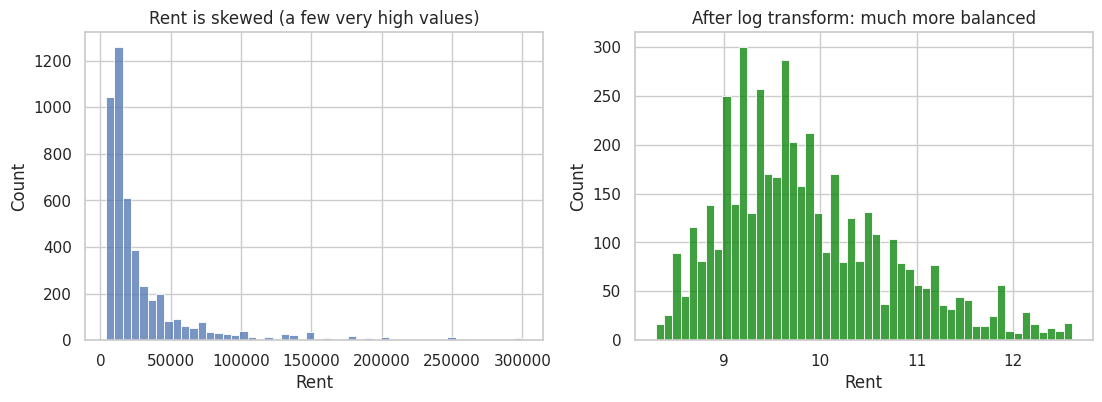

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(df["Rent"], bins=50, ax=ax[0]); ax[0].set_title("Rent is skewed (a few very high values)")
sns.histplot(np.log1p(df["Rent"]), bins=50, ax=ax[1], color="green"); ax[1].set_title("After log transform: much more balanced")
plt.show()

**Finding:** rent is *right-skewed*. Predicting `log(rent)` instead makes learning easier and is a standard trick — we use it in the model below.

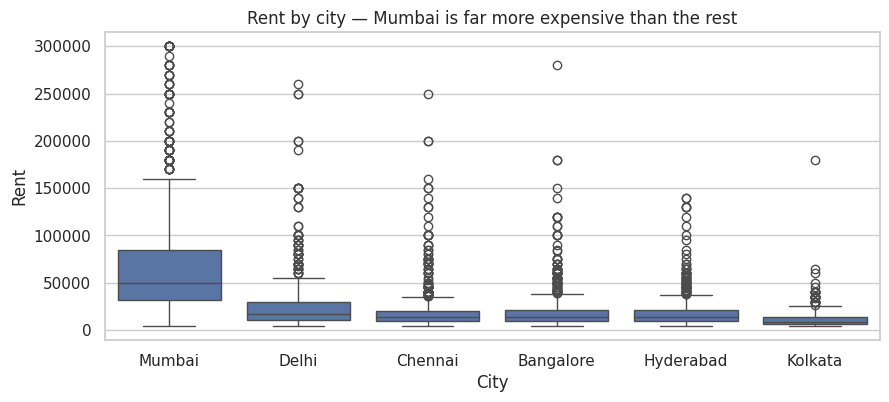

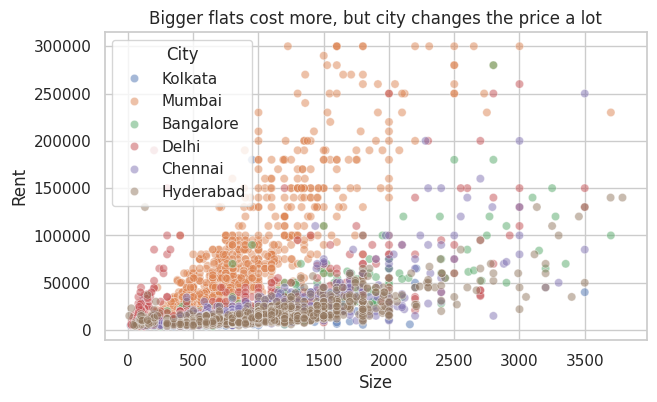

In [5]:
plt.figure(figsize=(10, 4))
order = df.groupby("City")["Rent"].median().sort_values(ascending=False).index
sns.boxplot(data=df, x="City", y="Rent", order=order)
plt.title("Rent by city — Mumbai is far more expensive than the rest"); plt.show()

plt.figure(figsize=(7, 4))
sns.scatterplot(data=df, x="Size", y="Rent", hue="City", alpha=0.5)
plt.title("Bigger flats cost more, but city changes the price a lot"); plt.show()

In [6]:
print("Median rent by furnishing status:")
print(df.groupby("Furnishing Status")["Rent"].median())
print("\nMedian rent by BHK:")
print(df.groupby("BHK")["Rent"].median())

Median rent by furnishing status:
Furnishing Status
Furnished         26000.0
Semi-Furnished    18000.0
Unfurnished       12000.0
Name: Rent, dtype: float64

Median rent by BHK:
BHK
1      9000.0
2     15000.0
3     32000.0
4    100000.0
5     50000.0
6     35000.0
Name: Rent, dtype: float64


## Step 5 — Prepare features and split the data
- **Features (inputs):** BHK, Size, Bathroom, floor numbers, Area Type, City, Furnishing Status, Tenant Preferred, Point of Contact.
- **Target (what we predict):** Rent.
- **Train/test split (80/20):** the model learns on 80% and is *tested on 20% it has never seen*. This tells us honestly how it will do on new flats.
- **One-hot encoding:** turns words like "Mumbai" into 0/1 columns the model can use.

In [7]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline

num_cols = ["BHK", "Size", "Bathroom", "floor_number", "total_floors"]
cat_cols = ["Area Type", "City", "Furnishing Status", "Tenant Preferred", "Point of Contact"]

X = df[num_cols + cat_cols]
y = df["Rent"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Train:", X_train.shape, " Test:", X_test.shape)

def make_reg(model):
    pre = ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols)], remainder="passthrough")
    return TransformedTargetRegressor(Pipeline([("prep", pre), ("model", model)]), func=np.log1p, inverse_func=np.expm1)

Train: (3717, 10)  Test: (930, 10)


## Step 6 — Model 1: Regression (predict the fair rent)
We compare 4 models, starting with a **baseline** (a dumb model that always guesses the median rent). *Any real model must beat the baseline — otherwise it learned nothing.*

**Metrics (how we score regression):**
- **R²** — how much of the rent variation the model explains (1.0 = perfect, 0 = no better than guessing the average).
- **MAE** — average mistake in ₹ (easy to explain to anyone).
- **RMSE** — like MAE but punishes big mistakes more.

In [8]:
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

models = {
    "Baseline (median)": DummyRegressor(strategy="median"),
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(n_estimators=300, min_samples_leaf=2, random_state=42, n_jobs=-1),
    "Gradient Boosting": HistGradientBoostingRegressor(random_state=42),
}
rows, fitted = [], {}
for name, m in models.items():
    pipe = make_reg(m).fit(X_train, y_train)
    pred = pipe.predict(X_test)
    fitted[name] = pipe
    rows.append({"Model": name,
                 "R²": round(r2_score(y_test, pred), 3),
                 "MAE (₹)": round(mean_absolute_error(y_test, pred)),
                 "RMSE (₹)": round(mean_squared_error(y_test, pred) ** 0.5)})
results = pd.DataFrame(rows).sort_values("R²", ascending=False).reset_index(drop=True)
results

,Model,R²,MAE (₹),RMSE (₹)
0,Gradient Boosting,0.776,9054,19384
1,Random Forest,0.769,9314,19664
2,Linear Regression,0.732,9694,21185
3,Baseline (median),-0.139,21264,43673


**Reading the table:** the best models explain roughly three-quarters of the variation in rent and cut the average error by more than half compared with the baseline. The remaining error exists because we don't know things like exact locality quality, building age or negotiation.

Best model: Gradient Boosting


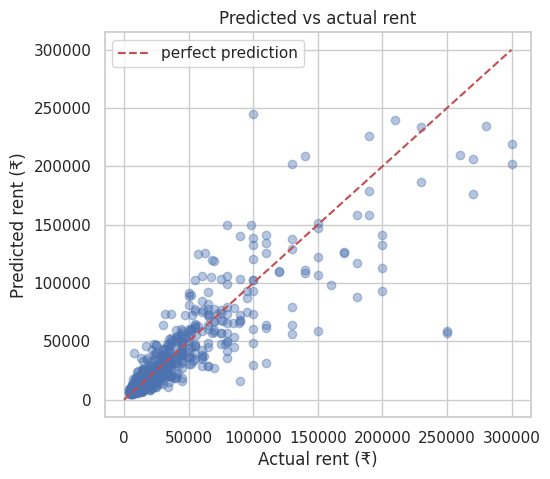

In [9]:
best_name = results.iloc[0]["Model"]
best_reg = fitted[best_name]
pred = best_reg.predict(X_test)
print("Best model:", best_name)

plt.figure(figsize=(5.5, 5))
plt.scatter(y_test, pred, alpha=0.4)
lim = [0, max(y_test.max(), pred.max())]
plt.plot(lim, lim, "r--", label="perfect prediction")
plt.xlabel("Actual rent (₹)"); plt.ylabel("Predicted rent (₹)"); plt.legend()
plt.title("Predicted vs actual rent"); plt.show()

## Step 7 — Which features matter most? (*Permutation importance*)
**What:** shuffle one column at a time and see how much the model gets worse. A big drop = an important feature.

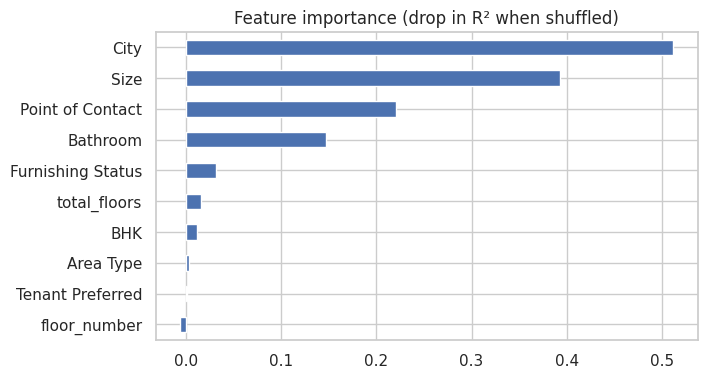

City                 0.512
Size                 0.393
Point of Contact     0.221
Bathroom             0.147
Furnishing Status    0.032
total_floors         0.016
BHK                  0.011
Area Type            0.003
Tenant Preferred     0.001
floor_number        -0.006
dtype: float64

In [10]:
from sklearn.inspection import permutation_importance
imp = permutation_importance(best_reg, X_test, y_test, n_repeats=5, random_state=42, scoring="r2")
imp_df = pd.Series(imp.importances_mean, index=X_test.columns).sort_values()
imp_df.plot(kind="barh", figsize=(7, 4), title="Feature importance (drop in R² when shuffled)")
plt.show()
imp_df.sort_values(ascending=False).round(3)

**Insight to say out loud:** *City* and *Size* drive rent the most, followed by *Point of Contact* and *Bathroom*. Furnishing matters, but much less than where the flat is. **Careful:** *Point of Contact* (owner / agent / builder) probably acts as a proxy — agents may list pricier flats — so it shows a *correlation*, not that the contact type causes higher rent. Mentioning this shows good judgement.

## Step 8 — Model 2: Classification (Bargain / Fair / Overpriced)
**Idea:** a listing is a **Bargain** if its rent is much *below* the fair rent the regression model predicts, **Overpriced** if much *above*, otherwise **Fair**.

**How we make labels without cheating:** we use **out-of-fold predictions** (5-fold cross-validation) — each flat's "fair rent" is predicted by a model that *never saw that flat*. Then:
- rent ÷ fair rent **> 1.25** → Overpriced
- rent ÷ fair rent **< 0.80** → Bargain
- otherwise → Fair

Then we train a **classifier** that takes the listing details **plus the listed rent** and learns to give the verdict.

⚠️ **Be honest in interviews:** the labels are derived from our own regression model (we don't have human-labelled "good deal" data). So this classifier is a *learned verdict layer*. A future improvement is to collect real user feedback as labels.

In [11]:
from sklearn.model_selection import cross_val_predict, KFold

oof_fair_rent = cross_val_predict(make_reg(RandomForestRegressor(n_estimators=300, min_samples_leaf=2, random_state=42, n_jobs=-1)),
                                  X, y, cv=KFold(5, shuffle=True, random_state=42))
ratio = y / oof_fair_rent
labels = np.where(ratio > 1.25, "Overpriced", np.where(ratio < 0.80, "Bargain", "Fair"))
print(pd.Series(labels).value_counts(normalize=True).round(3))

Fair          0.517
Bargain       0.244
Overpriced    0.240
Name: proportion, dtype: float64


In [12]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score

Xc = X.copy()
Xc["Listed_Rent"] = y
Xc["rent_per_sqft"] = y / df["Size"]
num_c = num_cols + ["Listed_Rent", "rent_per_sqft"]

Xc_train, Xc_test, yc_train, yc_test = train_test_split(Xc, labels, test_size=0.2, random_state=42, stratify=labels)
pre_c = ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols)], remainder="passthrough")

base = Pipeline([("p", pre_c), ("m", DummyClassifier(strategy="most_frequent"))]).fit(Xc_train, yc_train)
clf = Pipeline([("p", pre_c), ("m", RandomForestClassifier(n_estimators=150, min_samples_leaf=5, class_weight="balanced", random_state=42, n_jobs=-1))]).fit(Xc_train, yc_train)

for name, m in [("Baseline (always 'Fair')", base), ("Random Forest classifier", clf)]:
    p = m.predict(Xc_test)
    print(f"{name:28s} accuracy = {accuracy_score(yc_test, p):.3f} | macro-F1 = {f1_score(yc_test, p, average='macro'):.3f}")

print()
pred_c = clf.predict(Xc_test)
print(classification_report(yc_test, pred_c))

Baseline (always 'Fair')     accuracy = 0.516 | macro-F1 = 0.227
Random Forest classifier     accuracy = 0.703 | macro-F1 = 0.701

              precision    recall  f1-score   support

     Bargain       0.69      0.73      0.71       227
        Fair       0.76      0.67      0.71       480
  Overpriced       0.63      0.75      0.68       223

    accuracy                           0.70       930
   macro avg       0.69      0.72      0.70       930
weighted avg       0.71      0.70      0.70       930



**Metrics in simple words:**
- **Accuracy** — % of verdicts that were right.
- **Precision** — when the model says "Overpriced", how often is it really?
- **Recall** — of all truly overpriced flats, how many did we catch?
- **F1** — one number balancing precision and recall. We use **macro-F1** (average over the 3 classes) because the classes aren't equal in size.

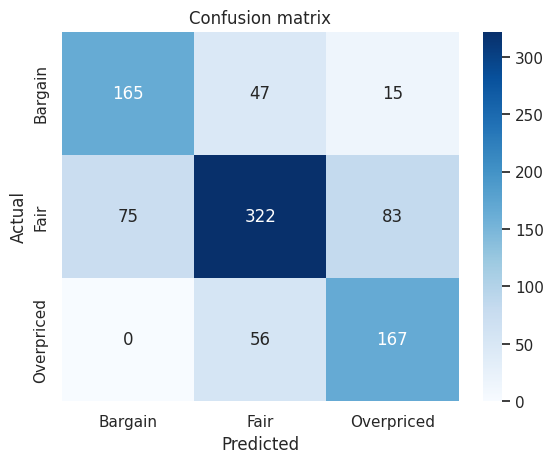

In [13]:
cm = confusion_matrix(yc_test, pred_c, labels=["Bargain", "Fair", "Overpriced"])
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=["Bargain", "Fair", "Overpriced"], yticklabels=["Bargain", "Fair", "Overpriced"])
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.title("Confusion matrix"); plt.show()

**Reading it:** the diagonal (top-left to bottom-right) is correct predictions. Most mistakes are between neighbouring classes (e.g. Fair ↔ Overpriced), not extreme ones (Bargain ↔ Overpriced), which is the safer kind of error.

## Step 9 — The product: `check_deal()`
Anyone can enter a listing and get the fair rent, the % difference, and the verdict.

In [14]:
best_reg.fit(X, y)  # final model: retrain on all data
clf.fit(Xc, labels)

def check_deal(bhk, size, bathroom, city, furnishing, listed_rent,
               floor_number=1, total_floors=4, area_type="Super Area",
               tenant="Bachelors/Family", contact="Contact Owner"):
    row = pd.DataFrame([{"BHK": bhk, "Size": size, "Bathroom": bathroom, "floor_number": floor_number,
                         "total_floors": total_floors, "Area Type": area_type, "City": city,
                         "Furnishing Status": furnishing, "Tenant Preferred": tenant, "Point of Contact": contact}])
    fair = float(best_reg.predict(row[num_cols + cat_cols])[0])
    row2 = row.copy(); row2["Listed_Rent"] = listed_rent; row2["rent_per_sqft"] = listed_rent / size
    verdict = clf.predict(row2[Xc.columns])[0]
    diff = (listed_rent - fair) / fair * 100
    return {"estimated_fair_rent": round(fair, -2), "listed_rent": listed_rent,
            "difference_%": round(diff, 1), "verdict": str(verdict)}

print(check_deal(bhk=2, size=900, bathroom=2, city="Delhi", furnishing="Semi-Furnished", listed_rent=30000))
print(check_deal(bhk=2, size=900, bathroom=2, city="Delhi", furnishing="Semi-Furnished", listed_rent=15000))
print(check_deal(bhk=2, size=900, bathroom=2, city="Delhi", furnishing="Semi-Furnished", listed_rent=11000))

{'estimated_fair_rent': 19600.0, 'listed_rent': 30000, 'difference_%': 53.3, 'verdict': 'Overpriced'}
{'estimated_fair_rent': 19600.0, 'listed_rent': 15000, 'difference_%': -23.3, 'verdict': 'Fair'}
{'estimated_fair_rent': 19600.0, 'listed_rent': 11000, 'difference_%': -43.8, 'verdict': 'Bargain'}


## Step 10 — Save the models (for a web app later)

In [15]:
joblib.dump(best_reg, "rent_regressor.joblib")
joblib.dump(clf, "deal_classifier.joblib")
print("Saved: rent_regressor.joblib, deal_classifier.joblib")

Saved: rent_regressor.joblib, deal_classifier.joblib


## ✅ Summary, limitations & next steps (read before your interview)

**Results (on unseen test data):** see the tables above — the regression model clearly beats the baseline, and the classifier clearly beats "always say Fair".

**Limitations (say these yourself — it shows maturity):**
- Only ~4,700 listings from 2022; prices change over time.
- We ignored *Area Locality* (too many unique values). Using it (e.g. target encoding) is an easy improvement.
- Classification labels come from our own regression model, not human judgement.
- The dataset has no building age, amenities, or distance to metro/college.

**Next steps:** add locality features → tune hyper-parameters → wrap in a **Flask API** → build a **React** page where users enter a flat and see the verdict → deploy.

### Likely interview questions
1. *Why log-transform the rent?* Rent is skewed; log makes it more balanced and reduces the effect of extreme values.
2. *Why a baseline?* To prove the model learned something real.
3. *Why train/test split?* To measure performance on unseen data and avoid fooling ourselves (overfitting).
4. *Why out-of-fold predictions for labels?* So no flat's label comes from a model that saw that same flat (avoids data leakage).
5. *R² vs MAE?* R² = share of variation explained; MAE = average error in rupees.
6. *Weakness of your classifier?* Labels are derived from the regression, not human-labelled.